<a href="https://colab.research.google.com/github/Ravikumar0604/Generative_modeling_casestudy/blob/main/RMDS_Homework5_notebook_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework Transfer Learning:

In this homework we are doing image classification with the Beans dataset. You can take help from the last week tutorial of image classification with transfer learning.

In [1]:
# Package imports.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset


from sklearn import preprocessing, model_selection
from tensorflow.keras.utils import to_categorical

**1. Load and prepare data**

We load Beans via the datasets package, resize to 115×115 to mirror the original, and collect NumPy arrays for simplicity.

In [2]:
# Load the dataset
dataset = load_dataset("darcieg/bean-disease-uganda")

IMG_SIZE = 115

images = []
labels = []

for split in ["train", "validation", "test"]:
    for sample in dataset[split]:
        if sample['image'].size == (500,500): # choosing only correct images
            img = np.array(sample["image"])
            img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy().astype(np.uint8)

            images.append(img)
            labels.append(sample["label"])

X_raw = np.stack(images)
labels_raw = np.array(labels)

README.md:   0%|          | 0.00/2.73k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/130 [00:00<?, ? examples/s]

**Class counts**

angular_leaf_spot: 432
bean_rust: 436
healthy: 427


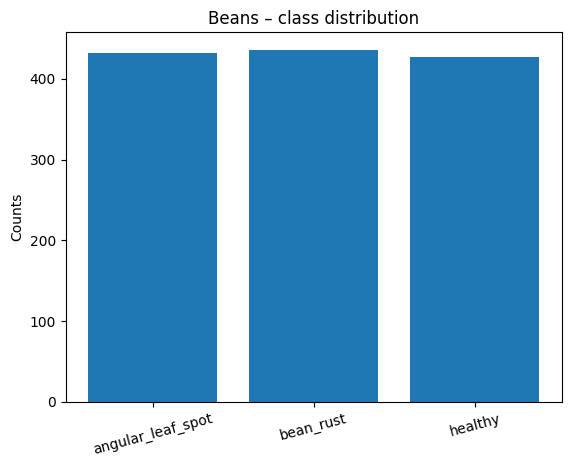

In [3]:
classes = ['angular_leaf_spot', 'bean_rust', 'healthy']
counts = [np.sum(labels_raw == i) for i in range(len(classes))]
for c, n in zip(classes, counts):
    print(f"{c}: {n}")
plt.bar(range(len(classes)), counts)
plt.xticks(range(len(classes)), classes, rotation=15)
plt.ylabel('Counts'); plt.title('Beans – class distribution')
plt.show()

**Peek at one sample & its channels**


The image has a size of 115 x 115 pixel, as expected, and is composed of 3 matrices that represent the RGB values of our colour image.

Make a plot of one sample and the three channels.

(115, 115, 3)


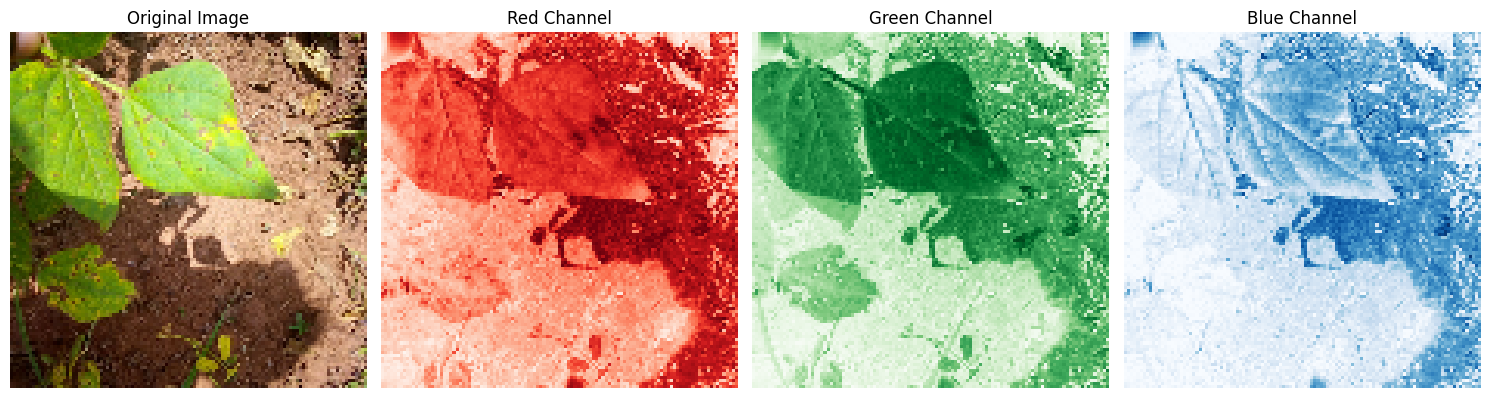

In [8]:
print(X_raw[0].shape)

sample_img = X_raw[0]

fig, axes = plt.subplots(1, 4, figsize=(15, 5))
# Original Image
axes[0].imshow(sample_img)
axes[0].set_title("Original Image")
axes[0].axis('off')

# Red Channel
axes[1].imshow(sample_img[:, :, 0], cmap='Reds')
axes[1].set_title("Red Channel")
axes[1].axis('off')

# Green Channel
axes[2].imshow(sample_img[:, :, 1], cmap='Greens')
axes[2].set_title("Green Channel")
axes[2].axis('off')

# Blue Channel
axes[3].imshow(sample_img[:, :, 2], cmap='Blues')
axes[3].set_title("Blue Channel")
axes[3].axis('off')

plt.tight_layout()
plt.show()

**2. Preprocessing**

Label encoding → one‑hot, normalisation, then train/validation split (70/30).

In [9]:
# Label encoding (already integers 0..2, but keep steps similar)
# Create an instance of the LabelEncoder class.
le = preprocessing.LabelEncoder()
# Apply fit_transform() method to perform integer encoding.
labels_encoded = le.fit_transform(labels_raw)
Y = to_categorical(labels_encoded, num_classes=3)

# Normalise to [0,1]
X = X_raw / 255.0

# Train/val split (students can tweak test_size)
X_train, X_val, Y_train, Y_val = model_selection.train_test_split(
    X, Y, test_size=0.30, random_state=42, stratify=Y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("Y_train shape:", Y_train.shape)
print("Y_val shape:", Y_val.shape)

X_train shape: (906, 115, 115, 3)
X_val shape: (389, 115, 115, 3)
Y_train shape: (906, 3)
Y_val shape: (389, 3)


**3. Define transfer‑learning model (VGG19)**

We keep the same structure as in tutorial: VGG19 base (frozen), Dense(256, relu) → Dense(num_classes, softmax). You can tweak pooling, learning rate, or fine‑tuning.

Print the model

Compile your model using Adam optimiser with learning rate 0.0001, also optimise the netwi=ork using categorical_crossentropy (Check TL tutorial notebookj)

In [10]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam

# Define the base VGG19 model with frozen weights
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
for layer in base_model.layers:
    layer.trainable = False

# Construct the head of the model
x = base_model.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(3, activation='softmax')(x)

# Combine base model and the head
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Print the summary
model.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 115, 115, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 115, 115, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 115, 115, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 57, 57, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 57, 57, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 57, 57, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 7, 7, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           77

 Total params: 21,205,059 (80.89 MB)

 Trainable params: 1,180,675 (4.50 MB)

 Non-trainable params: 20,024,384 (76.39 MB)

**Train the model**
Short run around 5 epochs to keep things quick

Use a batch size of 32 and train our network for 5 epochs.

Note: This will take a while, so I recommend you turn the verbosity to 1 so you can see the optimisation output.


In [11]:
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam

# Re-define base model and freeze weights
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
for layer in base_model.layers:
    layer.trainable = False

# Construct head
x = base_model.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
predictions = Dense(3, activation='softmax')(x)

# Create model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile model
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, Y_train,
    batch_size=32,
    epochs=5,
    validation_data=(X_val, Y_val),
    verbose=1
)

Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 238s 8s/step - accuracy: 0.5949 - loss: 0.8642 - val_accuracy: 0.7198 - val_loss: 0.7114
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 259s 8s/step - accuracy: 0.7572 - loss: 0.6050 - val_accuracy: 0.7532 - val_loss: 0.6177
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 273s 9s/step - accuracy: 0.7925 - loss: 0.5232 - val_accuracy: 0.7249 - val_loss: 0.6322
Epoch 4/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 258s 8s/step - accuracy: 0.8344 - loss: 0.4556 - val_accuracy: 0.7635 - val_loss: 0.5533
Epoch 5/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 258s 8s/step - accuracy: 0.8742 - loss: 0.3908 - val_accuracy: 0.7712 - val_loss: 0.5451


**Training curves**

We first plot the training curves, where we show the loss and accuracy estimates for our training and validation data as a function of the training epoch.

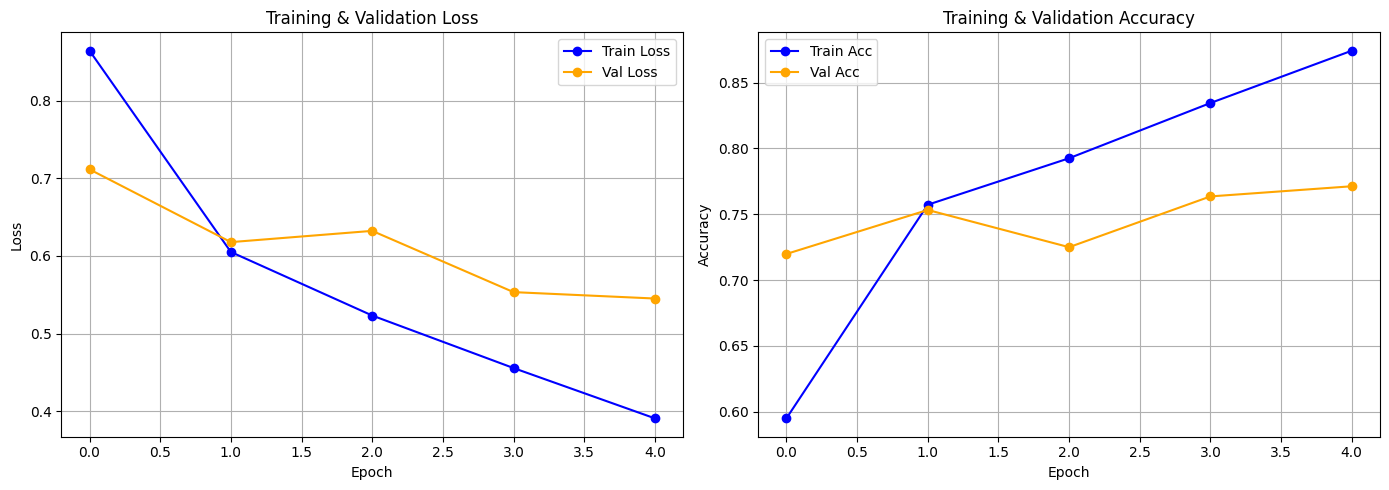

In [12]:
import matplotlib.pyplot as plt

# Create subplots for loss and accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot loss
ax1.plot(history.history['loss'], label='Train Loss', color='blue', marker='o')
ax1.plot(history.history['val_loss'], label='Val Loss', color='orange', marker='o')
ax1.set_title('Training & Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True)
ax1.legend()

# Plot accuracy
ax2.plot(history.history['accuracy'], label='Train Acc', color='blue', marker='o')
ax2.plot(history.history['val_accuracy'], label='Val Acc', color='orange', marker='o')
ax2.set_title('Training & Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

**Best Metrics**

Extract the best loss and accuracy of our models for the training and the validation datasets.

In [13]:
best_loss = np.min(history.history['loss'])
best_val_loss = np.min(history.history['val_loss'])
best_acc = np.max(history.history['accuracy'])
best_val_acc = np.max(history.history['val_accuracy'])

print(f'Best train loss: {best_loss:.4f}')
print(f'Best val loss: {best_val_loss:.4f}')
print(f'Best train acc: {best_acc:.4f}')
print(f'Best val acc: {best_val_acc:.4f}')

Best train loss: 0.3908
Best val loss: 0.5451
Best train acc: 0.8742
Best val acc: 0.7712


**Predictions & inspection**

Finally, we want to actually see some of the predictions on the validation data and visualise these. We do this using the model.predict() function in Keras.

In [14]:
pred = model.predict(X_val)
pred_labels = np.argmax(pred, axis=1)
true_labels = np.argmax(Y_val, axis=1)

right_idx = np.where(pred_labels == true_labels)[0].tolist()
wrong_idx = np.where(pred_labels != true_labels)[0].tolist()
print("Correct predictions:", len(right_idx))
print("Incorrect predictions:", len(wrong_idx))

13/13 ━━━━━━━━━━━━━━━━━━━━ 66s 5s/step
Correct predictions: 300
Incorrect predictions: 89


**Visualise a few correct / incorrect**

Draw 4 random samples from the correctly and incorrectly classified lists for plotting.



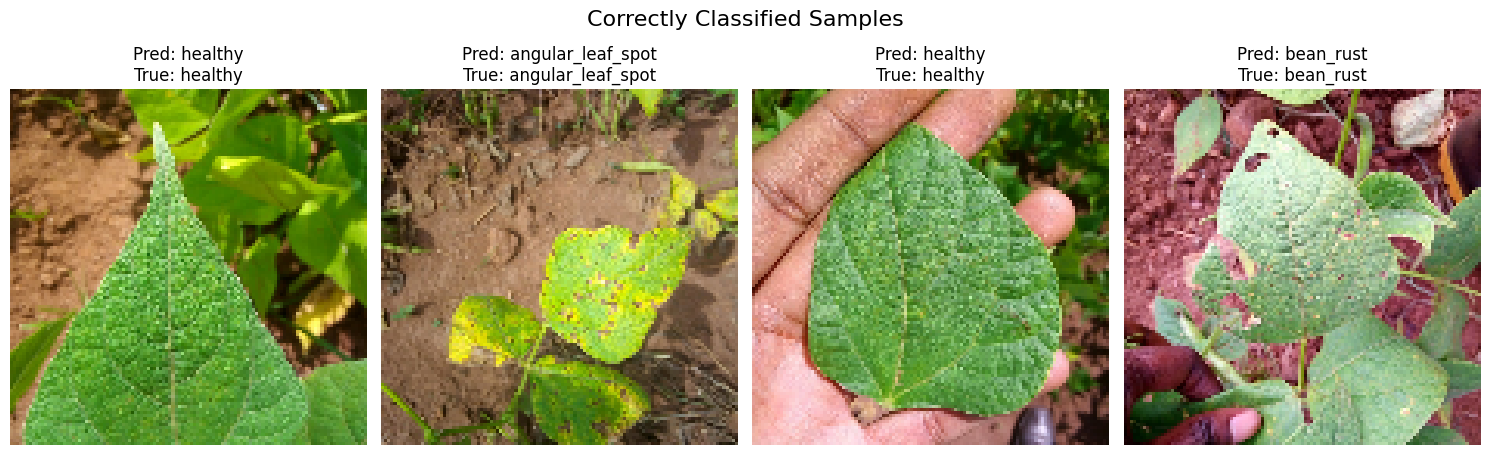

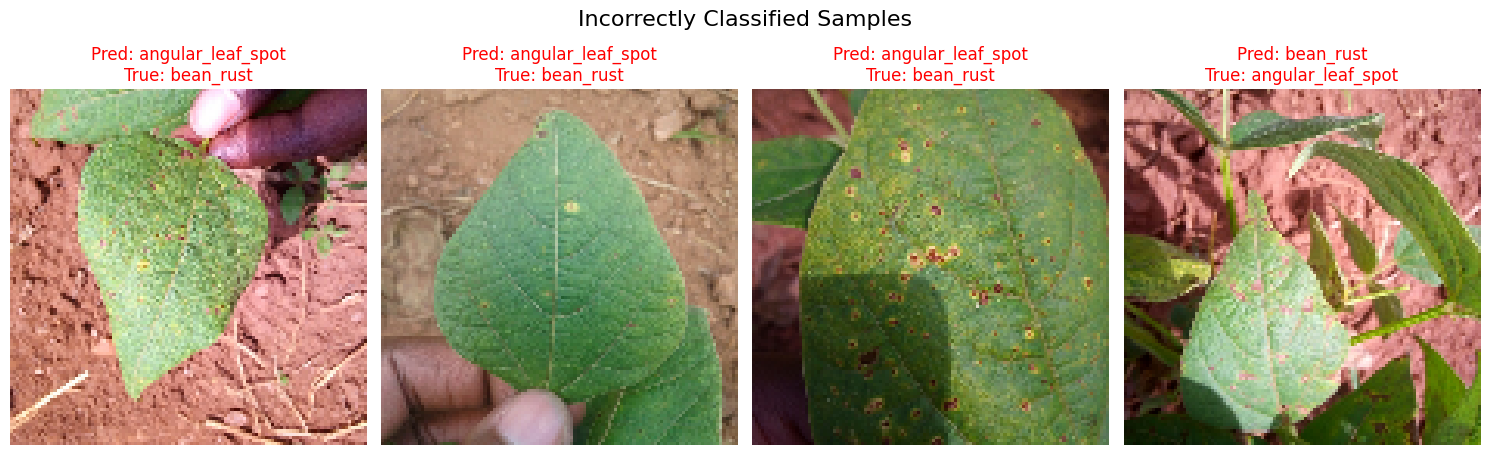

In [15]:
import random
random.seed(42)

# Sample 4 correct and 4 incorrect indices
sample_correct = random.sample(right_idx, min(4, len(right_idx)))
sample_incorrect = random.sample(wrong_idx, min(4, len(wrong_idx)))

# Plot correct predictions
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
fig.suptitle('Correctly Classified Samples', fontsize=16)
for i, idx in enumerate(sample_correct):
    axes[i].imshow(X_val[idx])
    pred_class = classes[pred_labels[idx]]
    true_class = classes[true_labels[idx]]
    axes[i].set_title(f"Pred: {pred_class}\nTrue: {true_class}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

# Plot incorrect predictions
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
fig.suptitle('Incorrectly Classified Samples', fontsize=16)
for i, idx in enumerate(sample_incorrect):
    axes[i].imshow(X_val[idx])
    pred_class = classes[pred_labels[idx]]
    true_class = classes[true_labels[idx]]
    axes[i].set_title(f"Pred: {pred_class}\nTrue: {true_class}", color='red')
    axes[i].axis('off')
plt.tight_layout()
plt.show()